In [1]:
import math
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint, odeint_adjoint
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda"
print(device)

cuda


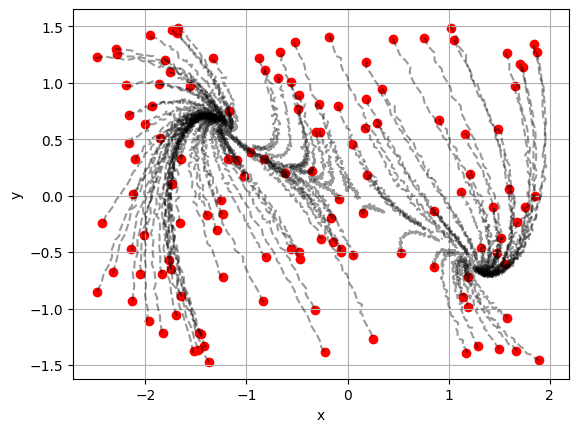

In [16]:
class FitzHughNagumo(nn.Module):
    def __init__(self, c=1.0, b=2.0, a=0.0, r=0.0, u=0.0):
        super().__init__()
        self.c = c
        self.b = b
        self.a = a
        self.r = r
        self.u = u

    def forward(self, t, z):
        x1 = z[..., 0]
        x2 = z[..., 1]

        dx1 = self.c * (x2 + x1 - (x1**3)/3 - self.r) + self.u
        dx2 = -(1/self.c) * (x1 - self.a + self.b * x2)

        return torch.stack([dx1, dx2], dim=-1)
   

def make_grid_dataset(T=3.0, step=60, noise_std=0.02,
                      nx=20, ny=20,
                      x_range=(-2.5, 2.0), y_range=(-1.5, 1.5)):
    gt = FitzHughNagumo().to(device)
    t = torch.linspace(0.0, T, step, device=device)

    xs = torch.linspace(x_range[0], x_range[1], nx, device=device)
    ys = torch.linspace(y_range[0], y_range[1], ny, device=device)
    X, Y = torch.meshgrid(xs, ys, indexing='ij')

    z0 = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=-1)

    with torch.no_grad():
        z_traj = odeint(gt, z0, t, method="dopri5")
        z_traj = z_traj.transpose(0, 1).contiguous()

        if noise_std > 0:
            z_traj = z_traj + noise_std * torch.randn_like(z_traj)

    return z0, t, z_traj

def make_random_dataset(n_traj=400, T=5.0, step=60, noise_std=0.02,
                        x_range=(-2.5, 2.0), y_range=(-1.5, 1.5)):
    gt = FitzHughNagumo().to(device)
    t = torch.linspace(0.0, T, step, device=device)

    x0 = x_range[0] + (x_range[1] - x_range[0]) * torch.rand(n_traj, device=device)
    y0 = y_range[0] + (y_range[1] - y_range[0]) * torch.rand(n_traj, device=device)
    z0 = torch.stack([x0, y0], dim=-1)

    with torch.no_grad():
        z_traj = odeint(gt, z0, t, method="dopri5")
        z_traj = z_traj.transpose(0, 1).contiguous()

        if noise_std > 0:
            z_traj = z_traj + noise_std * torch.randn_like(z_traj)

    return z0, t, z_traj

z0_train, t_eval, Z_train = make_grid_dataset(
    T=2.0,
    step=100,
    noise_std=0.01,
    nx=30,
    ny=30,
    x_range=(-2.5, 2.0),
    y_range=(-1.5, 1.5 )
)

z0_test, _, Z_test = make_random_dataset(
    n_traj=600,
    T=2.0,
    step=100,
    noise_std=0.01,
    x_range=(-2.5, 2.0),
    y_range=(-1.5, 1.5)
)

train_load = DataLoader(
    TensorDataset(z0_train, Z_train),
    batch_size=128,
    shuffle=True
)

test_load = DataLoader(
    TensorDataset(z0_test, Z_test),
    batch_size=128,
    shuffle=False
)

torch.save({
    "z0_train": z0_train.cpu(),
    "Z_train": Z_train.cpu(),

    "z0_test": z0_test.cpu(),
    "Z_test": Z_test.cpu(),

    "t_eval": t_eval.cpu()
}, "dataset.pt")



for z0_batch, Z_batch in test_load:
    for i in range (Z_batch.size(0)):
        x = Z_batch[i,:,0].cpu().numpy()
        y = Z_batch[i,:,1].cpu().numpy()
        plt.plot(x,y,'k--',alpha=0.4)

   
    plt.scatter(z0_batch[:, 0].cpu().numpy(),
                z0_batch[:, 1].cpu().numpy(),
                color='red')
    break

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.show()

class ODEmodel(nn.Module):
    def __init__(self,state_dim=2, hidden=64, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim+(1 if time_dependent else 0)
        self.net=nn.Sequential(
            nn.Linear(in_dim, hidden),nn.Softplus(),
            nn.Linear(hidden, hidden), nn.Softplus(),
            nn.Linear(hidden,state_dim),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)
        

    def forward(self, t,z):
        if z.dim()==1:
            z = z.unsqueeze(0)
        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z
        return self.net(h)
    
class NeuralODE(nn.Module):
     def __init__(self, func, use_adjoint, rtol=1e-3, atol=1e-4, method="dopri5"):
            super().__init__()
            self.func = func
            self.use_adjoint = use_adjoint
            self.rtol = rtol
            self.atol = atol
            self.method = method


     def forward(self,z0,t):
            solver= odeint_adjoint if self.use_adjoint else odeint
            Z = solver(self.func, z0, t , rtol=self.rtol, atol=self.atol, method=self.method)
            return Z.transpose(0, 1).contiguous()
def mse ( z_hat, z_true):
    return torch.mean((z_hat-z_true)**2)

def evaluate(model, loader, t_eval):
    model.eval()
    mse_sum, count = 0.0, 0
    with torch.no_grad():
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred=model(z0,t_eval)
            mse_sum += mse(Z_pred, Z).item()*z0.size(0)
            count +=z0.size(0)
        return mse_sum/count
    
true_equilibria = torch.tensor([
    [0.0, 0.0], #saddle
    [1.2247449, -0.6123724],#stable
    [-1.2247449, 0.6123724],#stable
], dtype=torch.float32, device=device)
def jacobian_2d(func, x, t0=0.0):
   

    x = x.clone().detach().requires_grad_(True)
    t0 = torch.tensor(float(t0), device=x.device, dtype=x.dtype)

    
    y = func(t0, x.unsqueeze(0)).squeeze(0)

    J = torch.zeros(2, 2, device=x.device, dtype=x.dtype)

    for i in range(2):
        grad = torch.autograd.grad(y[i], x, retain_graph=True)[0]
        J[i] = grad

    return J

def find_equilibrium(func, x0, t0=0.0, steps=300, lr=0.02):
    x = x0.clone().detach().to(device).requires_grad_(True)
    opt = torch.optim.Adam([x], lr=lr)
    t0 = torch.tensor(float(t0), device=device)

    for _ in range(steps):
        v = func(t0, x.unsqueeze(0)).squeeze(0)
        loss = (v**2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()

    with torch.no_grad():
        res = torch.norm(func(t0, x.unsqueeze(0)).squeeze(0)).item()
    return x.detach(), res

def find_equilibrium_near_target(func, x_target, t0=0.0, n_starts=8, steps=300, lr=0.02, radius=0.3):
    best_x = None
    best_score = float("inf")
    best_res = None

    for _ in range(n_starts):
        x0 = x_target + radius * torch.randn_like(x_target)
        x_eq, res = find_equilibrium(func, x0, t0=t0, steps=steps, lr=lr)

        dist = torch.norm(x_eq - x_target).item()
        score = dist + 0.1 * res   # главный приоритет — близость к target

        if score < best_score:
            best_score = score
            best_x = x_eq
            best_res = res

    return best_x, best_res

def analyze_equilibrium(func, epoch, t0=0.0):
    print(f"\nEpoch {epoch}")
    eq_errors = []
    eigvals_all = []

    for i, x_true_eq in enumerate(true_equilibria, 1):
        x0 = x_true_eq + 0.2 * torch.randn_like(x_true_eq)

        x_eq, res = find_equilibrium_near_target(  func, x_true_eq, t0=t0, n_starts=8, steps=300, lr=0.02, radius=0.3)
        err = torch.norm(x_eq - x_true_eq).item()
        eq_errors.append(err)
       

        J = jacobian_2d(func, x_eq, t0=t0)
        eigvals = torch.linalg.eigvals(J)
        eigvals_all.append(eigvals.detach().cpu())
        
        
        print(f"\nEquilibrium {i}")
        print("x_equilibrium      =", x_eq.detach().cpu().numpy())
        print("x_true_equilibrium =", x_true_eq.detach().cpu().numpy())
        print("||x_eq - x_true||  =", err)
        print("residual ||f(x)||  =", res)
        print("eigenvalues        =", eigvals.detach().cpu().numpy())

    return eq_errors,eigvals_all
        
def train(model, loader, t_eval, epochs=600, lr=1e-3, clip_grad=5.0, tag="NODE"):
    optim = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    test_losses = []
    eq_errors_history = []
    eigvals_history = []
    epoch_marks = []

    for ep in range(1, epochs + 1):
        model.train()
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred = model(z0, t_eval)
            loss = mse(Z_pred, Z)

            optim.zero_grad()
            loss.backward()
            if clip_grad:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
            optim.step()

        tr = evaluate(model, train_load, t_eval)
        te = evaluate(model, test_load, t_eval)

        train_losses.append(tr)
        test_losses.append(te)

        if ep % 10 == 0:
            eq_errors, eigvals_all = analyze_equilibrium(model.func, epoch=ep, t0=0.0)
            eq_errors_history.append(eq_errors)
            eigvals_history.append(eigvals_all)
            epoch_marks.append(ep)

            print(f"[{tag}] Epoch {ep:03d} | train {tr:.6f} | test {te:.6f}")

    return model, train_losses, test_losses, eq_errors_history, eigvals_history, epoch_marks

In [17]:
func_adj = ODEmodel().to(device)
node_adj = NeuralODE(func_adj, use_adjoint=True).to(device)

print("Training Neural ODE ...")
node_adj, train_losses, test_losses, eq_errors_history, eigvals_history, epoch_marks = train(
    node_adj, train_load, t_eval, tag="ADJ"
)

print("\nFinal MSE")
print("Train:", evaluate(node_adj, train_load, t_eval))
print("Test :", evaluate(node_adj, test_load,  t_eval))

torch.save({
    "model_state": node_adj.state_dict(),
    "func_state": node_adj.func.state_dict(),  
}, "node_adj.pth")

Training Neural ODE ...

Epoch 10

Equilibrium 1
x_equilibrium      = [-0.07509444 -0.11975549]
x_true_equilibrium = [0. 0.]
||x_eq - x_true||  = 0.141352578997612
residual ||f(x)||  = 0.00014832046872470528
eigenvalues        = [-0.31526476+0.26461983j -0.31526476-0.26461983j]

Equilibrium 2
x_equilibrium      = [-0.06575947 -0.12574133]
x_true_equilibrium = [ 1.2247449 -0.6123724]
||x_eq - x_true||  = 1.3792067766189575
residual ||f(x)||  = 0.00237029860727489
eigenvalues        = [-0.3154055+0.26475662j -0.3154055-0.26475662j]

Equilibrium 3
x_equilibrium      = [-0.07456237 -0.1201274 ]
x_true_equilibrium = [-1.2247449  0.6123724]
||x_eq - x_true||  = 1.3636258840560913
residual ||f(x)||  = 8.720726896171982e-07
eigenvalues        = [-0.31527293+0.26462767j -0.31527293-0.26462767j]
[ADJ] Epoch 010 | train 0.148426 | test 0.134541

Epoch 20

Equilibrium 1
x_equilibrium      = [ 0.09178116 -0.05809523]
x_true_equilibrium = [0. 0.]
||x_eq - x_true||  = 0.10862245410680771
residual ||f

In [18]:
eigvals_history_cpu = [
    [eig.cpu() for eig in snapshot]
    for snapshot in eigvals_history
]

torch.save({
    "model_state": node_adj.state_dict(),
    "func_state": node_adj.func.state_dict(),
    "train_losses": train_losses,
    "test_losses": test_losses,
    "eq_errors_history": eq_errors_history,
    "eigvals_history": eigvals_history_cpu,
    "epoch_marks": epoch_marks,
}, "node_adj.pth") 

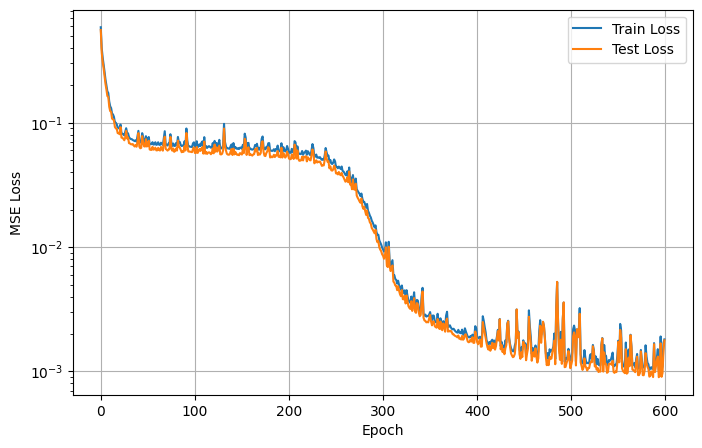

In [19]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid()
plt.show()

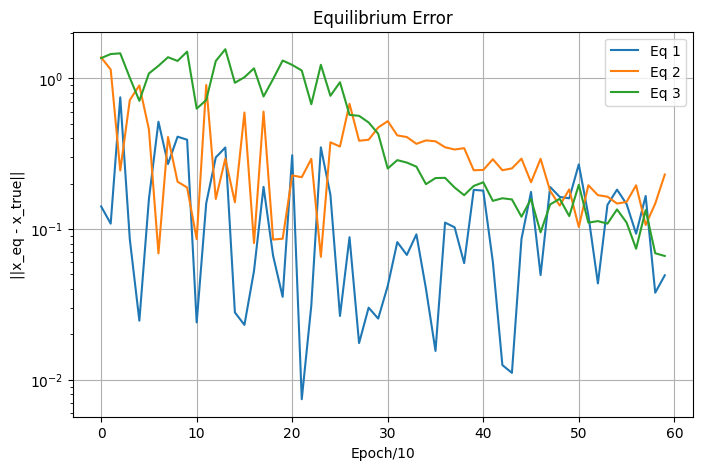

In [20]:
import numpy as np

eq_errors_history = np.array(eq_errors_history)  # shape (epochs, 4)

plt.figure(figsize=(8,5))

for i in range(eq_errors_history.shape[1]):
    plt.plot(eq_errors_history[:, i], label=f"Eq {i+1}")

plt.yscale("log")
plt.xlabel("Epoch/10")
plt.ylabel("||x_eq - x_true||")
plt.title("Equilibrium Error")
plt.legend()
plt.grid()

plt.show()

In [21]:
import matplotlib.pyplot as plt

def plot_eigs_simple(eigvals_history, epoch_marks):
    eigvals_history = np.array(eigvals_history)

    # true eigenvalues 
    true_eigs = [
        [0.6180, -1.6180],                    # (0,0)
        [-1.25 + 0.6614j, -1.25 - 0.6614j],   # right
        [-1.25 + 0.6614j, -1.25 - 0.6614j],   # left
    ]

    for eq_idx in range(3):
        re1, re2 = [], []
        im1, im2 = [], []

        for i in range(len(eigvals_history)):
            lam = eigvals_history[i][eq_idx]

            re1.append(lam[0].real)
            re2.append(lam[1].real)
            im1.append(lam[0].imag)
            im2.append(lam[1].imag)

        plt.figure(figsize=(6,4))

        
        plt.plot(epoch_marks, re1, label="Re λ1")
        plt.plot(epoch_marks, re2, label="Re λ2")
        plt.plot(epoch_marks, im1, "--", label="Im λ1")
        plt.plot(epoch_marks, im2, "--", label="Im λ2")

        lam_true = true_eigs[eq_idx]

        plt.axhline(lam_true[0].real, color="green", linestyle="-", alpha=0.7, label="true Re")
        plt.axhline(lam_true[1].real, color="green", linestyle="-", alpha=0.7)

        if abs(np.imag(lam_true[0])) > 1e-6:
            plt.axhline(lam_true[0].imag, color="red", linestyle=":", alpha=0.7, label="true Im")
            plt.axhline(lam_true[1].imag, color="red", linestyle=":", alpha=0.7)

        plt.axhline(0, color="black", linestyle="--")

        plt.title(f"Equilibrium {eq_idx+1}")
        plt.xlabel("Epoch")
        plt.ylabel("Value")
        plt.legend()
        plt.grid()
        plt.show()

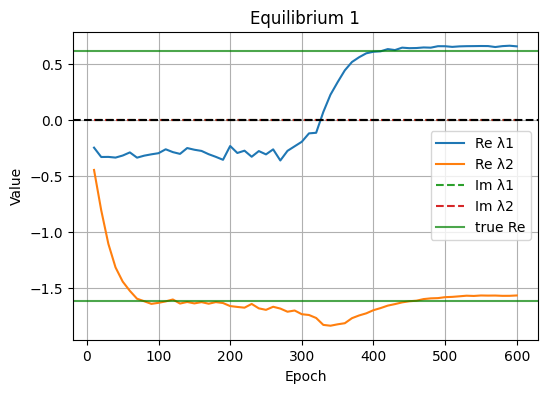

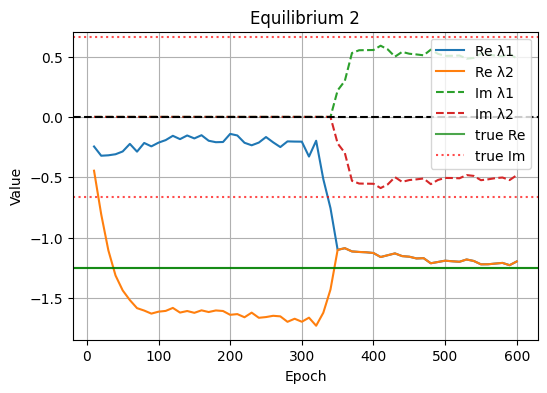

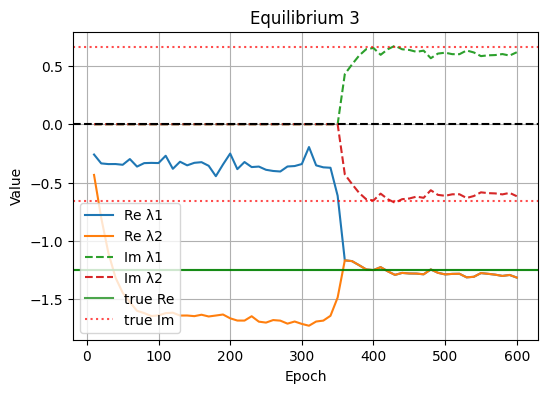

In [28]:
plot_eigs_simple(eigvals_history, epoch_marks)

In [22]:
def plot_vector_fields_shifted(true_func, learned_func,
                              shift_y=0.6,
                              x_range=(-2.5, 2.0), y_range=(-1.5, 1.5),
                              nx=20, ny=20, t0=0.0, device="cpu"):

    xs = torch.linspace(x_range[0], x_range[1], nx, device=device)
    ys = torch.linspace(y_range[0], y_range[1], ny, device=device)
    X, Y = torch.meshgrid(xs, ys, indexing='ij')

    Z = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=-1)

    with torch.no_grad():
        V_true = true_func(torch.tensor(t0, device=device), Z).cpu().numpy()
        V_learn = learned_func(torch.tensor(t0, device=device), Z).cpu().numpy()

    Xn = Z[:, 0].cpu().numpy()
    Yn = Z[:, 1].cpu().numpy()

    plt.figure(figsize=(8, 6))

    # оригинал (без сдвига)
    plt.quiver(Xn, Yn,
               V_true[:, 0], V_true[:, 1],
               color='black', alpha=0.8, label='True system')

    # обученная (сдвиг по y)
    plt.quiver(Xn, Yn + shift_y,
               V_learn[:, 0], V_learn[:, 1],
               color='red', alpha=0.6, label=f'Learned (+{shift_y} y)')

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Vector fields (shifted for clarity)")
    plt.grid()
    plt.legend()
    plt.show()

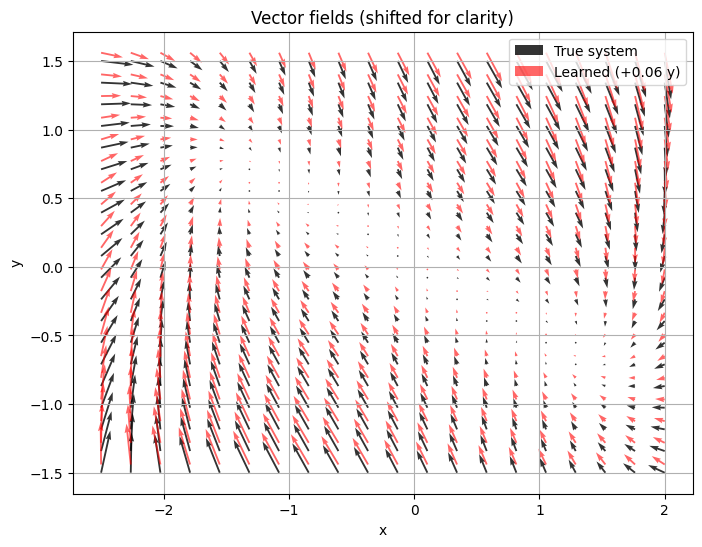

In [24]:
gt = FitzHughNagumo().to(device)
func = node_adj.func
plot_vector_fields_shifted(
    true_func=gt,
    learned_func=func,
    shift_y=0.06,
    device=device
)